In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
import contextily as ctx
from shapely.geometry import Point
from mpl_toolkits.mplot3d import Axes3D
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from mpl_toolkits.mplot3d import Axes3D
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingRegressor
from features_maker import NearestCityTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from utilities import cross_val_price_metrics_from_log

from utilities import *
import features_maker

# Projet prédiction de loyer
### Raphaël Thieffry, Antonin Russac, Ethan Puyaubreau

---

### Récupération des données
Nous avons récupérés les données des locations d'appartements en France à l'aide de l'API de [Bien'ici](https://www.bienici.com/), qui est un agrégateur d'annonces immobilières.  
Nous avons ainsi récupéré un CSV de plus de 2000 annonces. Ceci en est un petit aperçu :

In [3]:
csv_file = "rents.csv"
df = pd.read_csv(csv_file)

df.head(3)

,id,reference,account_type,account_name,customer_id,city,postal_code,department_code,district_name,district_label,...,ad_created_by_pro,on_market,leading_ad,photos_count,virtual_tours_count,title,description,exposition,year_of_construction,transaction_type
0,ics-jol_JOLIS_M2_loc-GES00120002-876,GES00120002-876,agency,NaN,gilles-trignat-residence-1698152662756,Sassenage,38360,38,Sassenage,Sassenage,...,True,True,False,14,0,NaN,"Sassenage, rue Charles de Gaulle, secteur Oval...",Nord-est,2009.0,rent
1,ics-jol_JOLIS_M2_loc-GES00380002-876,GES00380002-876,agency,NaN,gilles-trignat-residence-1698152662756,Sassenage,38360,38,Sassenage,Sassenage,...,True,True,True,8,0,NaN,"studio avec jardin et parking - SASSENAGE, Sec...",Nord-est,2004.0,rent
2,ics-jol_JOLIS_M2_loc-GES00380003-876,GES00380003-876,agency,NaN,gilles-trignat-residence-1698152662756,Sassenage,38360,38,Sassenage,Sassenage,...,True,True,False,11,0,NaN,"SASSENAGE, secteur OVALIE. Dans une propriété ...",Est,NaN,rent


### Nettoyage des données
Dans l'objectif de déterminer les loyers, nous allons maintenant supprimer les features non-pertinentes dans la décision du loyer (par exemple : le nom de l'agence immobilière, l'id de l'annonce, ...)  
Le **prix** est bien sûr la variable cible sur laquelle nous voulons faire la régression.  
Il ne reste ainsi que 28 métriques :
| Localisation         | Surface & Pièces         | Équipements Intérieurs   | Équipements Extérieurs | Énergie & Coûts         |
|----------------------|--------------------------|--------------------------|------------------------|-------------------------|
| city                 | surface                  | elevator                 | balconies             | energy_class            |
| postal_code          | rooms                    | disabled_access          | terraces              | energy_value            |
| department_code      | bedrooms                 | furnished                | parking_places        | ghg_class                |
| lat                  | bathrooms                | duplex                   |                        | ghg_value                |
| lon                  | showers                  |                          |                        | energy_min_cost         |
| floor                |                          |                          |                        | energy_max_cost         |
|                      |                          |                          |                        | heating_type            |
|                      |                          |                          |                        | new_property             |
|                      |                          |                          |                        | description             |


In [4]:
pertinent_features = ["city", "postal_code", "department_code", "lat", "lon", "surface", "rooms", "bedrooms", "bathrooms", "showers", "floor", "balconies", "terraces", "parking_places", "cellars", "elevator", "disabled_access","furnished", "duplex", "energy_class", "energy_value", "ghg_class", "ghg_value", "energy_min_cost", "energy_max_cost","heating_type", "new_property", "description"] # columns for x
target_features = ["price"]
real_columns = ["price", "lat", "lon", "surface", "rooms", "bedrooms", "bathrooms", "showers", "floor", "balconies", "terraces", "parking_places", "cellars", "energy_value", "ghg_value", "energy_min_cost", "energy_max_cost"]

In [5]:
#prices = df[target_features].copy()
df = df[pertinent_features+target_features].copy()

# Counts NaN on each columns
df.isna().sum()

city                  0
postal_code           0
department_code       0
lat                   0
lon                   0
surface               4
rooms                 2
bedrooms             86
bathrooms           354
showers             253
floor               151
balconies           604
terraces            610
parking_places      560
cellars             678
elevator            153
disabled_access     505
furnished            85
duplex             4350
energy_class          0
energy_value        201
ghg_class             9
ghg_value           208
energy_min_cost     521
energy_max_cost     520
heating_type        225
new_property          0
description           0
price                 0
dtype: int64

### Suppression des lignes avec des champs "NaN" et préparation des données

In [6]:
df.loc[df["duplex"].isna(), "duplex"] = False # tout ceux dont le duplex est pas renseigné c'est que c'en est pas

In [7]:
df.notna().all(axis=1).sum() # les colonnes sans champ NaN <=> champs utilisables
df = df.dropna().copy()

In [8]:
df.shape # 28 features + la variable cible

(3374, 29)

#### On remarque que près du quart des données ont été retirées

### Visualisation des données (1)
Mise en relation de la variable cible avec les différentes features (numériques).

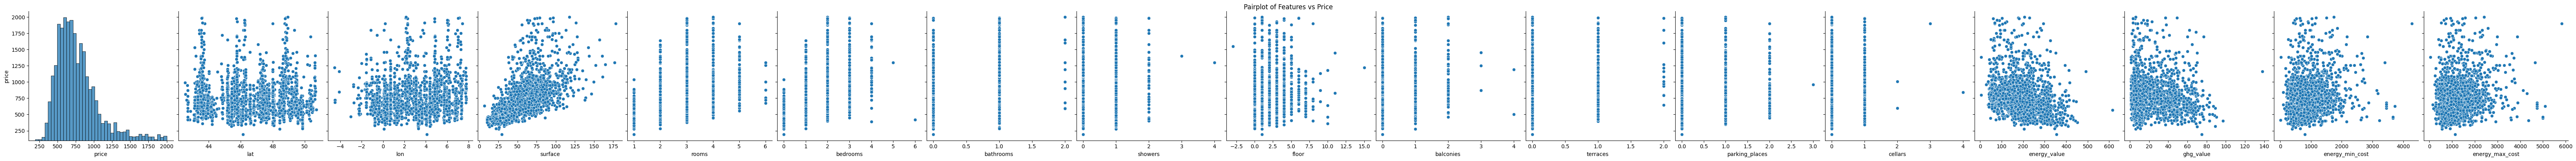

In [9]:
# Select the relevant columns
pairplot_data = df[real_columns]

# Generate the pairplot
sns.pairplot(pairplot_data, x_vars=real_columns, y_vars=["price"], height=4, aspect=1, kind="scatter")
plt.suptitle("Pairplot of Features vs Price", y=1.02)
plt.show()

### Visualisation des données (2)
Mise en relation de la valeur cible (Axe vertical) avec les données géographiques.

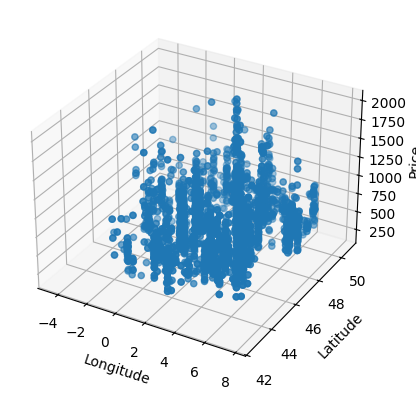

In [10]:
map3DFrance(df)

### Visualisation des données (3)
Superposition de la carte de France pour une meilleur visualisation. Les loyers sont en couleurs.

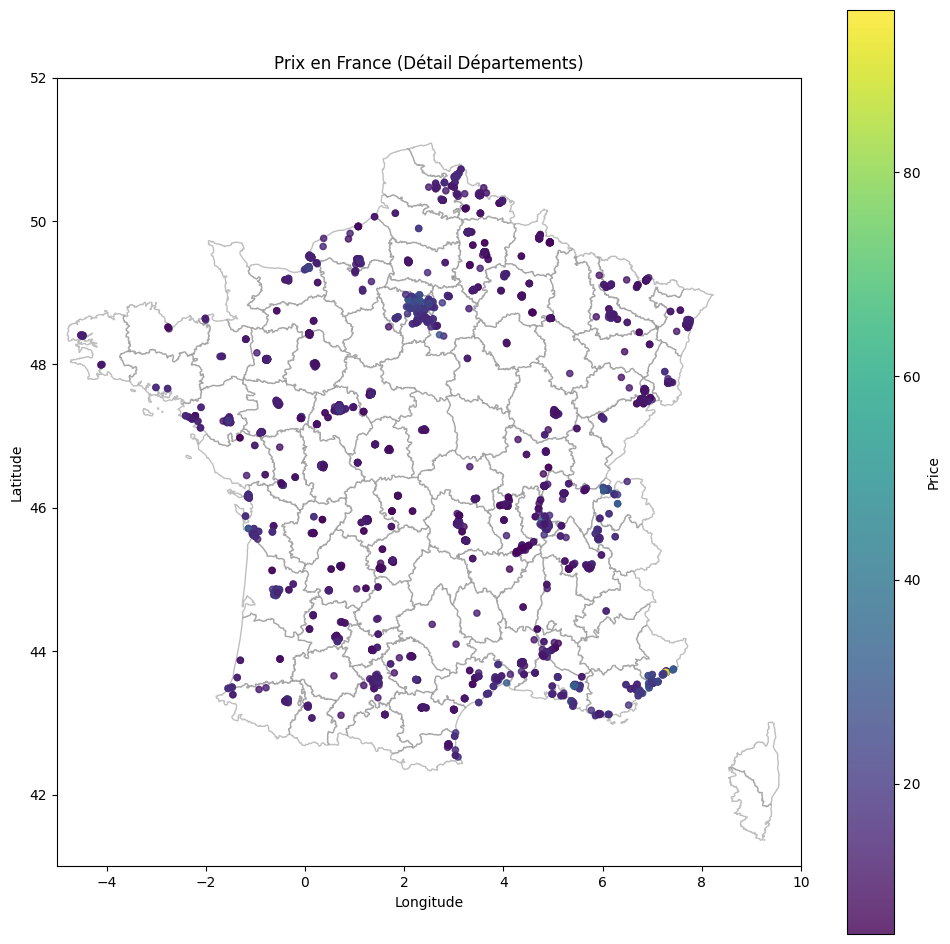

In [11]:
map2DFrance(df)

### Visualisation des données (4)
Focus sur la région parisienne.

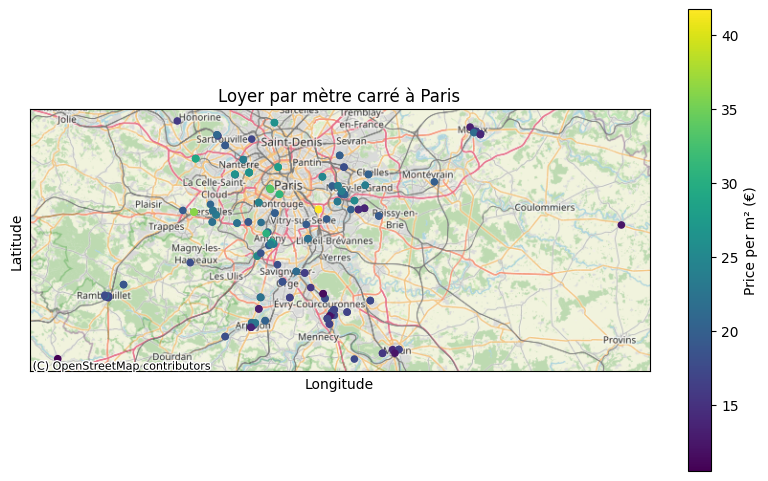

In [12]:
map2DParis(df)

### Premiers essais
Première approche naïve, en s'appuyant uniquement sur les données géographiques (longitude et latitude), avec un modèle de régression linéaire.

Mean Squared Error: 80534.18002350863
R² Score: 0.022214796818414984


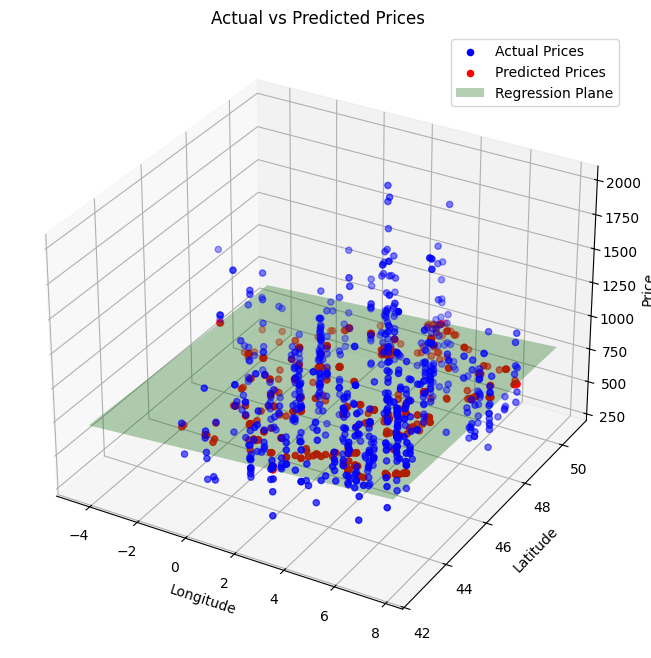

In [13]:
# Prepare data
X = df[["lon", "lat"]] ; y = df["price"]
# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Train model
model = LinearRegression() ; model.fit(X_train, y_train)
# Predictions
y_pred = model.predict(X_test)
# Metrics
mse = mean_squared_error(y_test, y_pred) ; r2 = r2_score(y_test, y_pred) ; print(f"Mean Squared Error: {mse}\nR² Score: {r2}")
# Visualize predictions vs actual in 3D
fig = plt.figure(figsize=(10, 8)) ; ax = fig.add_subplot(111, projection='3d') ; ax.scatter(X_test["lon"], X_test["lat"], y_test, c='b', label='Actual Prices')
ax.scatter(X_test["lon"], X_test["lat"], y_pred, c='r', label='Predicted Prices') ; # Add the regression plane
lon_range = np.linspace(X["lon"].min(), X["lon"].max(), 10) ; lat_range = np.linspace(X["lat"].min(), X["lat"].max(), 10)
lon_grid, lat_grid = np.meshgrid(lon_range, lat_range) ; price_grid = model.intercept_ + model.coef_[0] * lon_grid + model.coef_[1] * lat_grid
ax.plot_surface(lon_grid, lat_grid, price_grid, alpha=0.3, color='green', label='Regression Plane') ; ax.set_xlabel('Longitude') ; ax.set_ylabel('Latitude') ; ax.set_zlabel('Price')
ax.set_title('Actual vs Predicted Prices') ; ax.legend() ; plt.show()

### Premiers essais
Même chose, mais avec une régression polynomiale de degré 10.

Polynomial Regression (degree 10) - Mean Squared Error: 64735.18232740102
Polynomial Regression (degree 10) - R² Score: 0.2140342971578305


/home/user/cours/Pr-diction-Immobili-re/env/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


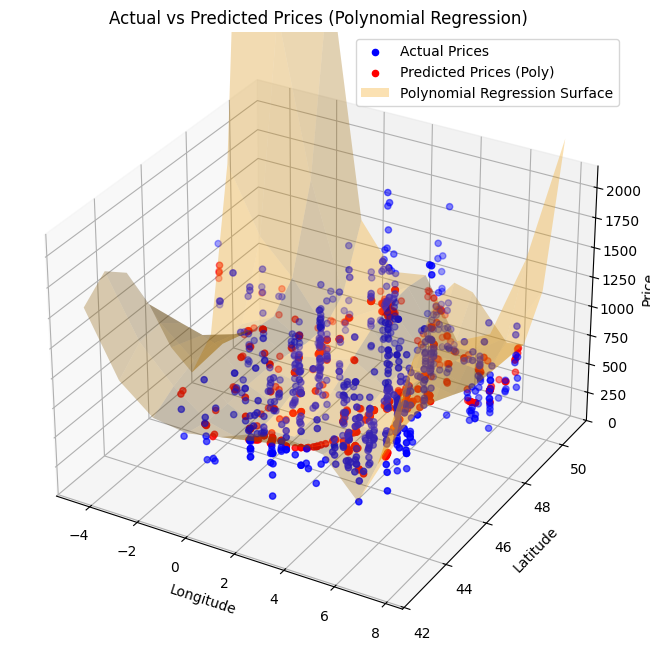

In [14]:
poly = PolynomialFeatures(degree=10) ; X_poly = poly.fit_transform(X)
X_train_poly, X_test_poly, y_train, y_test = train_test_split(X_poly, y, test_size=0.2, random_state=42)
model_poly = LinearRegression() ; model_poly.fit(X_train_poly, y_train)
y_pred_poly = model_poly.predict(X_test_poly) ; mse_poly = mean_squared_error(y_test, y_pred_poly)
r2_poly = r2_score(y_test, y_pred_poly) ; print(f"Polynomial Regression (degree 10) - Mean Squared Error: {mse_poly}")
print(f"Polynomial Regression (degree 10) - R² Score: {r2_poly}") ; # Visualize polynomial regression predictions vs actual in 3D
fig = plt.figure(figsize=(10, 8)) ; ax = fig.add_subplot(111, projection='3d') ; ax.scatter(X_test["lon"], X_test["lat"], y_test, c='b', label='Actual Prices')
ax.scatter(X_test["lon"], X_test["lat"], y_pred_poly, c='r', label='Predicted Prices (Poly)')
# Add the polynomial regression surface
price_grid_poly = model_poly.predict(poly.transform(np.c_[lon_grid.ravel(), lat_grid.ravel()])).reshape(lon_grid.shape)
ax.plot_surface(lon_grid, lat_grid, price_grid_poly, alpha=0.3, color='orange', label='Polynomial Regression Surface')
ax.set_xlabel('Longitude') ; ax.set_ylabel('Latitude') ; ax.set_zlabel('Price') ; ax.set_zlim(0, np.max(y_test)*1.1)
ax.set_title('Actual vs Predicted Prices (Polynomial Regression)') ; ax.legend() ; plt.show()

### Premiers essais
Comparaison avec une régression linéaire sur l'ensemble des features numériques

Linear Regression with all features - Mean Squared Error: 51538.05862078554
Linear Regression with all features - R² Score: 0.37426380816941285


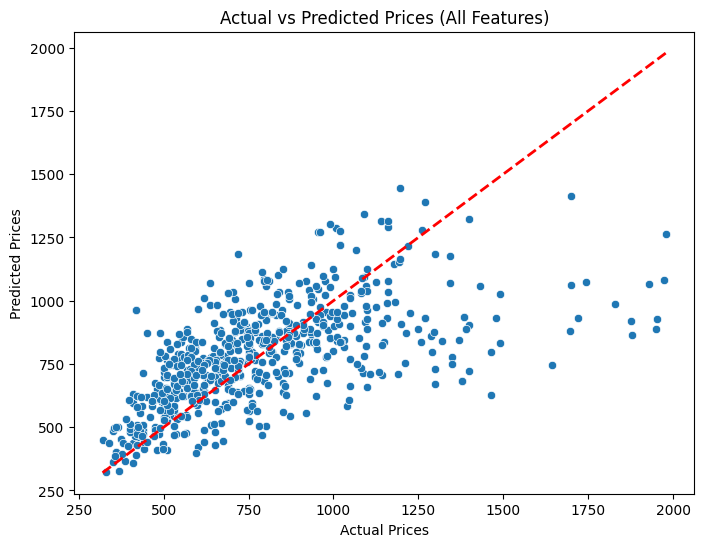

In [15]:
X_all = df[real_columns].drop(columns=["price"])
y_all = df["price"]
X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(X_all, y_all, test_size=0.2, random_state=42)
model_all = LinearRegression()
model_all.fit(X_train_all, y_train_all)
y_pred_all = model_all.predict(X_test_all)
mse_all = mean_squared_error(y_test_all, y_pred_all)
r2_all = r2_score(y_test_all, y_pred_all)
print(f"Linear Regression with all features - Mean Squared Error: {mse_all}")
print(f"Linear Regression with all features - R² Score: {r2_all}")

# Plot predicted vs actual prices 
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test_all, y=y_pred_all)
plt.plot([y_test_all.min(), y_test_all.max()], [y_test_all.min(),
            y_test_all.max()], '--', lw=2, color='red')
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Prices (All Features)")
plt.show()

### Premier essais
Réduction de la dimensionalité avec PCA. Nouvel échec

PCA + Linear Regression - Mean Squared Error: 53213.509658252544
PCA + Linear Regression - R² Score: 0.353921746791098


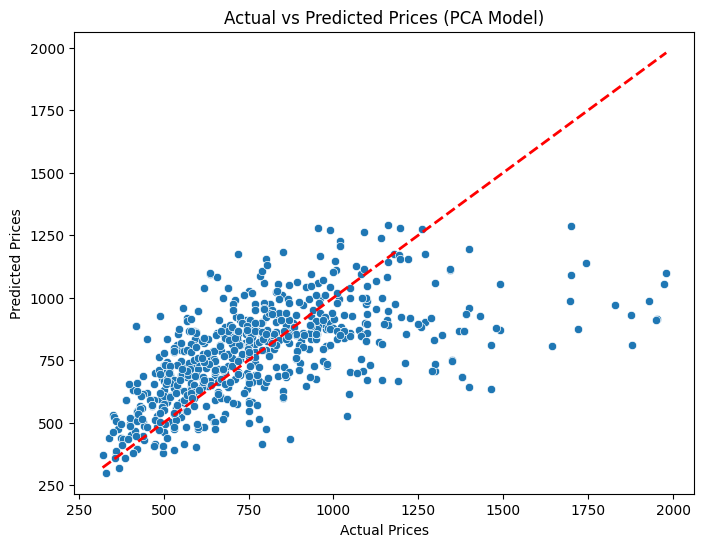

In [16]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)
pca = PCA(n_components=5) # reduce to 5 components

X_pca = pca.fit_transform(X_scaled)
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(X_pca, y_all, test_size=0.2, random_state=42)
model_pca = LinearRegression()
model_pca.fit(X_train_pca, y_train_pca) ; y_pred_pca = model_pca.predict(X_test_pca)
mse_pca = mean_squared_error(y_test_pca, y_pred_pca) ; r2_pca = r2_score(y_test_pca, y_pred_pca)
print(f"PCA + Linear Regression - Mean Squared Error: {mse_pca}") ; print(f"PCA + Linear Regression - R² Score: {r2_pca}")
# Plot predicted vs actual prices for PCA model
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test_pca, y=y_pred_pca)
plt.plot([y_test_pca.min(), y_test_pca.max()], [y_test_pca.min(),
            y_test_pca.max()], '--', lw=2, color='red')
plt.xlabel("Actual Prices") ; plt.ylabel("Predicted Prices") ; plt.title("Actual vs Predicted Prices (PCA Model)") ; plt.show()

### Approche systématique : comparaison de plusieurs autres modèles
Ici, nous avons essayé plusieurs modèles de manière grossière (sans cross-validation, pour la performance), en les comparant grâce aux métriques R² et MSE.  

In [17]:
compare_models(X_train_all, X_test_all, y_train_all, y_test_all)

Entraînement de Linear Regression...
Entraînement de Ridge Regression...


Entraînement de Random Forest...
Entraînement de Gradient Boosting...


,Modèle,RMSE (€),MAE (€),R²
2,Random Forest,104.942045,67.800146,0.866291
3,Gradient Boosting,105.018016,73.948992,0.866097
0,Linear Regression,227.019952,159.164729,0.374264
1,Ridge Regression,227.025363,159.180886,0.374234


### Exploration approfondie
Utilisation du grid search et cross validation systématique pour comparer les hyperparamètres.  
Utilisation d'une pipeline et ajout d'un transformeur pour exploiter les features catégorielles.

Best parameters: {'regressor__learning_rate': 0.2, 'regressor__max_depth': 5, 'regressor__n_estimators': 800}
Grid Search + GBR - Mean Squared Error: 4983.236176682683
Grid Search + GBR - R² Score: 0.9394973091413216


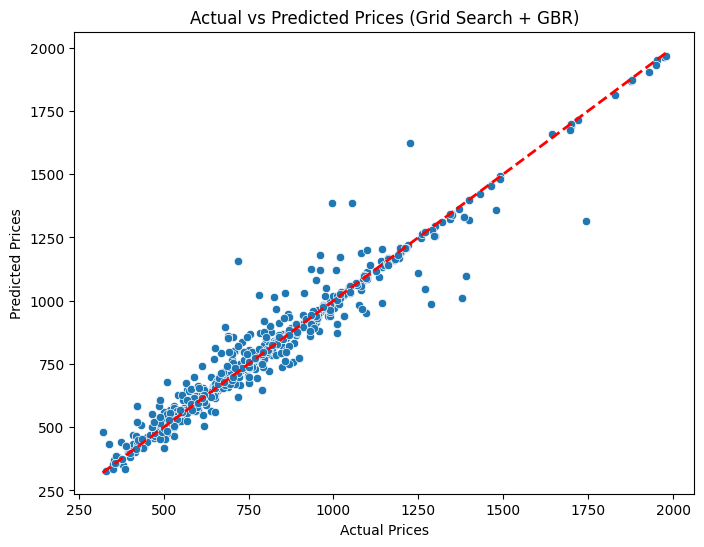

In [18]:
# pipeline with preprocessing and selected model
#columns : (['city', 'postal_code', 'department_code', 'lat', 'lon', 'surface', 'rooms', 'bedrooms', 'bathrooms', 'showers', 'floor', 'balconies', 'terraces', 'parking_places', 'cellars', 'elevator', 'disabled_access', 'furnished', 'duplex', 'energy_class', 'energy_value', 'ghg_class', 'ghg_value', 'energy_min_cost', 'energy_max_cost', 'heating_type', 'new_property', 'description'], ['price'])
numerical_features = ["lat", "lon", "surface", "rooms", "bedrooms", "bathrooms", "showers", "floor", "balconies", "terraces", "parking_places", "cellars", "energy_value", "ghg_value", "energy_min_cost", "energy_max_cost"]
categorical_features = ["city", "postal_code", "department_code", "elevator", "disabled_access", "furnished", "duplex", "energy_class", "ghg_class", "heating_type",  "new_property"]
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])
# pipeline with free hyper parameters for grid-search
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor())
])
from sklearn.model_selection import GridSearchCV
param_grid = {
    'regressor__n_estimators': [100, 200, 300, 500, 800],
    'regressor__learning_rate': [0.05, 0.1, 0.2, 0.5],
    'regressor__max_depth': [3, 5, 7, 10]
}
grid_search = GridSearchCV(pipeline, param_grid, cv=5, n_jobs=-1, scoring='r2')

X = df[pertinent_features]
y = df["price"]
X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(X, y, test_size=0.2, random_state=42)

grid_search.fit(X_train_all, y_train_all)
print(f"Best parameters: {grid_search.best_params_}")
best_model = grid_search.best_estimator_
y_pred_grid = best_model.predict(X_test_all)
mse_grid = mean_squared_error(y_test_all, y_pred_grid)
r2_grid = r2_score(y_test_all, y_pred_grid)
print(f"Grid Search + GBR - Mean Squared Error: {mse_grid}")
print(f"Grid Search + GBR - R² Score: {r2_grid}")
# Plot predicted vs actual prices for Grid Search model
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test_all, y=y_pred_grid)
plt.plot([y_test_all.min(), y_test_all.max()], [y_test_all.min(),
            y_test_all.max()], '--', lw=2, color='red')
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Prices (Grid Search + GBR)")
plt.show()

In [19]:
best_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['lat', 'lon', 'surface',
                                                   'rooms', 'bedrooms',
                                                   'bathrooms', 'showers',
                                                   'floor', 'balconies',
                                                   'terraces', 'parking_places',
                                                   'cellars', 'energy_value',
                                                   'ghg_value',
                                                   'energy_min_cost',
                                                   'energy_max_cost']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['city', 'postal_code',
                                                   'department_code',
                                                   'elevator',
                                                   'disabled_access',
                                                   'furnished', 'duplex',
                                                   'energy_class', 'ghg_class',
                                                   'heating_type',
                                                   'new_property'])])),
                ('regressor',
                 GradientBoostingRegressor(learning_rate=0.2, max_depth=5,
                                           n_estimators=800))])

### Importance des features

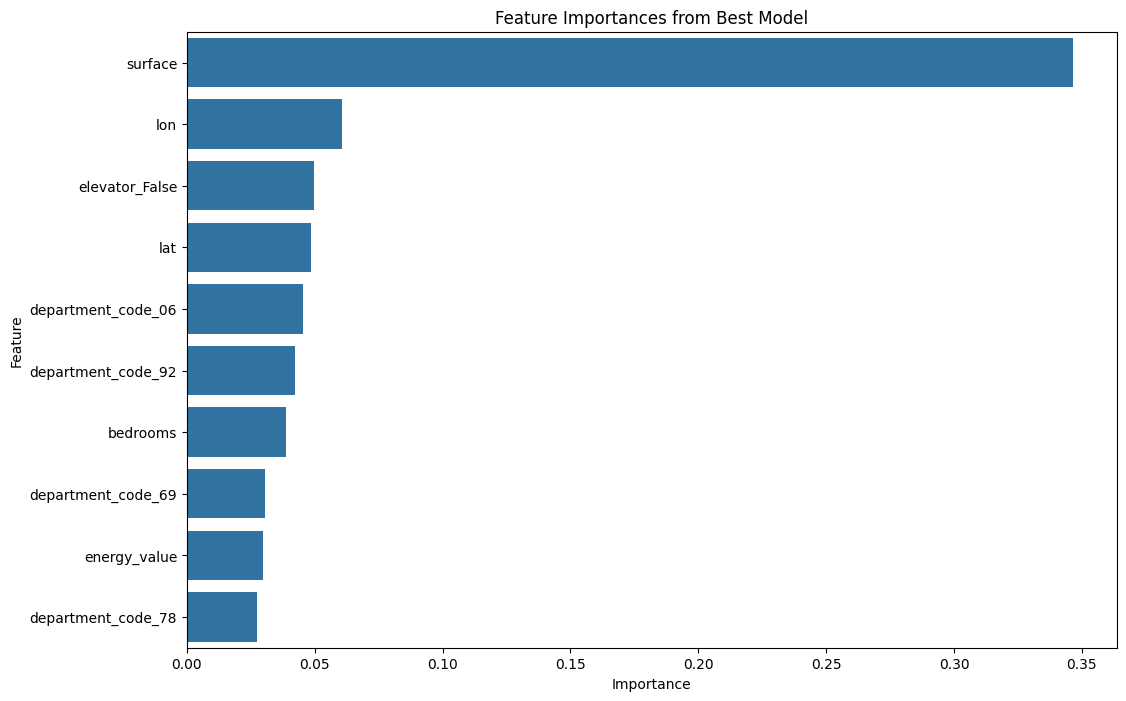

In [20]:
feature_names = numerical_features + list(best_model.named_steps['preprocessor'].transformers_[1][1].get_feature_names_out(categorical_features))
importances = best_model.named_steps['regressor'].feature_importances_
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
# head 10 features
f = feature_importance_df.head(10)
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=f)
plt.title('Feature Importances from Best Model')
plt.show()

In [21]:
numerical_features = ["lat", "lon", "surface", "rooms", "bedrooms", "bathrooms", "showers", "floor", "balconies", "terraces", "parking_places", "cellars", "energy_value", "ghg_value", "energy_min_cost", "energy_max_cost"]
categorical_features = ["city", "postal_code", "department_code", "elevator", "disabled_access", "furnished", "duplex", "energy_class", "ghg_class", "heating_type",  "new_property"]

### Ajout d'une itération PCA normalisée 
Utilisation de toutes les feature "réelles", on applique la PCA dessus pour obtenir 10 features abstraites (réduction de dimensions).  
On applique la PCA dessus.

Best parameters: {'preprocessor__num__pca__n_components': 15, 'regressor__learning_rate': 0.2, 'regressor__max_depth': 5, 'regressor__n_estimators': 500}
Grid Search + GBR - Mean Squared Error: 7772.2539450696
Grid Search + GBR - R² Score: 0.905635161360799


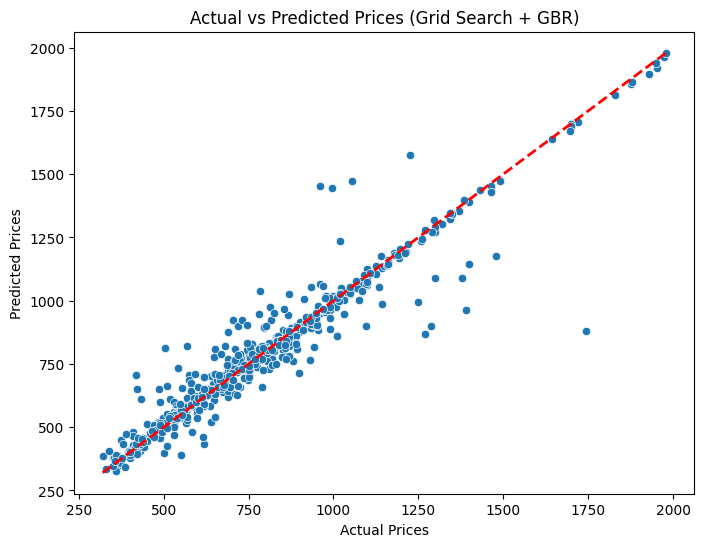

In [22]:
#columns : (['city', 'postal_code', 'department_code', 'lat', 'lon', 'surface', 'rooms', 'bedrooms', 'bathrooms', 'showers', 'floor', 'balconies', 'terraces', 'parking_places', 'cellars', 'elevator', 'disabled_access', 'furnished', 'duplex', 'energy_class', 'energy_value', 'ghg_class', 'ghg_value', 'energy_min_cost', 'energy_max_cost', 'heating_type', 'new_property', 'description'], ['price'])
numerical_features = ["lat", "lon", "surface", "rooms", "bedrooms", "bathrooms", "showers", "floor", "balconies", "terraces", "parking_places", "cellars", "energy_value", "ghg_value", "energy_min_cost", "energy_max_cost"]
categorical_features = ["city", "postal_code", "department_code", "elevator", "disabled_access", "furnished", "duplex", "energy_class", "ghg_class", "heating_type",  "new_property"]
numeric_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA())
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numerical_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

# pipeline with free hyper parameters for grid-search
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor())
])
from sklearn.model_selection import GridSearchCV
param_grid = {
    'preprocessor__num__pca__n_components': [5, 10, 15],
    'regressor__n_estimators': [100, 200, 300, 500],
    'regressor__learning_rate': [0.05, 0.1, 0.2, 0.5],
    'regressor__max_depth': [3, 5, 7, 10]
}
grid_search = GridSearchCV(pipeline, param_grid, cv=5, n_jobs=-1, scoring='r2')

X = df[pertinent_features]
y = df["price"]
X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(X, y, test_size=0.2, random_state=42)

grid_search.fit(X_train_all, y_train_all)
print(f"Best parameters: {grid_search.best_params_}") ; best_model = grid_search.best_estimator_
y_pred_grid = best_model.predict(X_test_all) ; mse_grid = mean_squared_error(y_test_all, y_pred_grid) ; r2_grid = r2_score(y_test_all, y_pred_grid)
print(f"Grid Search + GBR - Mean Squared Error: {mse_grid}") ; print(f"Grid Search + GBR - R² Score: {r2_grid}")
# Plot predicted vs actual prices for Grid Search model
plt.figure(figsize=(8, 6)) ; sns.scatterplot(x=y_test_all, y=y_pred_grid) ; plt.plot([y_test_all.min(), y_test_all.max()], [y_test_all.min(),y_test_all.max()], '--', lw=2, color='red')
plt.xlabel("Actual Prices") ; plt.ylabel("Predicted Prices") ; plt.title("Actual vs Predicted Prices (Grid Search + GBR)") ; plt.show()

## Les conclusions sont que la PCA n'est pas idéale pour de telles données.
## On peut essayer de rajouter des features, d'utiliser des modèles plus adapté à un mix categories/réel

best_model

### Ajout de nouvelles features (étape de la pipeline)
Une alternative à Longitude/Latitude sont la distance à la plus grande ville, le logarithme de la population de la ville la plus proche ainsi que le rang de la ville la plus proche. (trouvables dans features_maker.py)  
Cela fait suite à notre constat ci-dessus du manque d'influence et d'expressivité de la latitude et de la longitude sur le montant du loyer en tant que données brutes lors de l'entrainement des modèles.

(2699, 27) (675, 27) (2699,) (675,)
Best parameters: {'preprocessor__geo__geo_features__top_n': 10, 'regressor__learning_rate': 0.1, 'regressor__max_depth': 5, 'regressor__n_estimators': 800}
Grid Search + GBR + NearestCity - Mean Squared Error: 5944.788450658393
Grid Search + GBR + NearestCity - R² Score: 0.9278228674905267


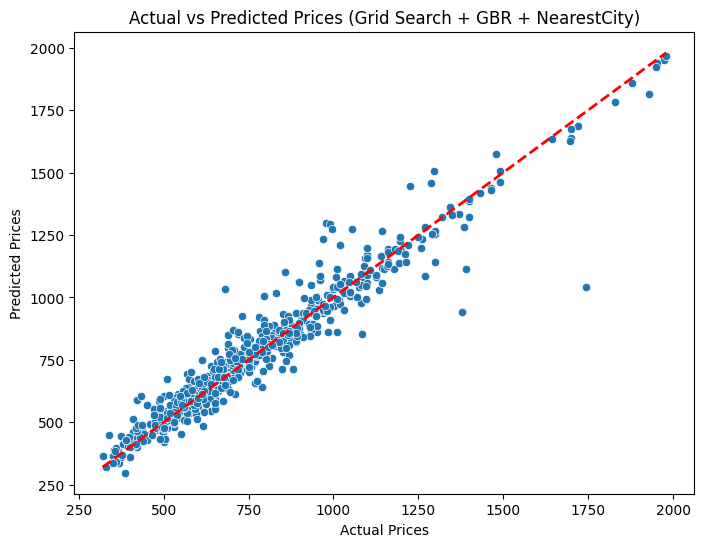

In [23]:
geo_features = ["lat", "lon"]

geo_pipeline = Pipeline([
    ("geo_features", NearestCityTransformer())
])

preprocessor = ColumnTransformer([
    ('geo', geo_pipeline, geo_features),
    ('num', "passthrough", [f for f in numerical_features if f not in geo_features]),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

param_grid = {
    "preprocessor__geo__geo_features__top_n": [5, 10, 20, 50],
    "regressor__n_estimators": [200, 500, 800],
    "regressor__learning_rate": [0.05, 0.1],
    "regressor__max_depth": [3, 5, 7]
}

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor())
])
grid_search = GridSearchCV(pipeline, param_grid, cv=5, n_jobs=-1, scoring='r2')
X = df[numerical_features + categorical_features]
y = df["price"]
X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train_all.shape, X_test_all.shape, y_train_all.shape, y_test_all.shape)

grid_search.fit(X_train_all, y_train_all)
print(f"Best parameters: {grid_search.best_params_}")
best_model = grid_search.best_estimator_
y_pred_grid = best_model.predict(X_test_all)
mse_grid = mean_squared_error(y_test_all, y_pred_grid)
r2_grid = r2_score(y_test_all, y_pred_grid)
print(f"Grid Search + GBR + NearestCity - Mean Squared Error: {mse_grid}")
print(f"Grid Search + GBR + NearestCity - R² Score: {r2_grid}")
# Plot predicted vs actual prices for Grid Search model
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test_all, y=y_pred_grid)
plt.plot([y_test_all.min(), y_test_all.max()], [y_test_all.min(),
            y_test_all.max()], '--', lw=2, color='red')
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Prices (Grid Search + GBR + NearestCity)")
plt.show()

### Importance des features
On se rend compte que ces nouvelles features ont une influence considérables !

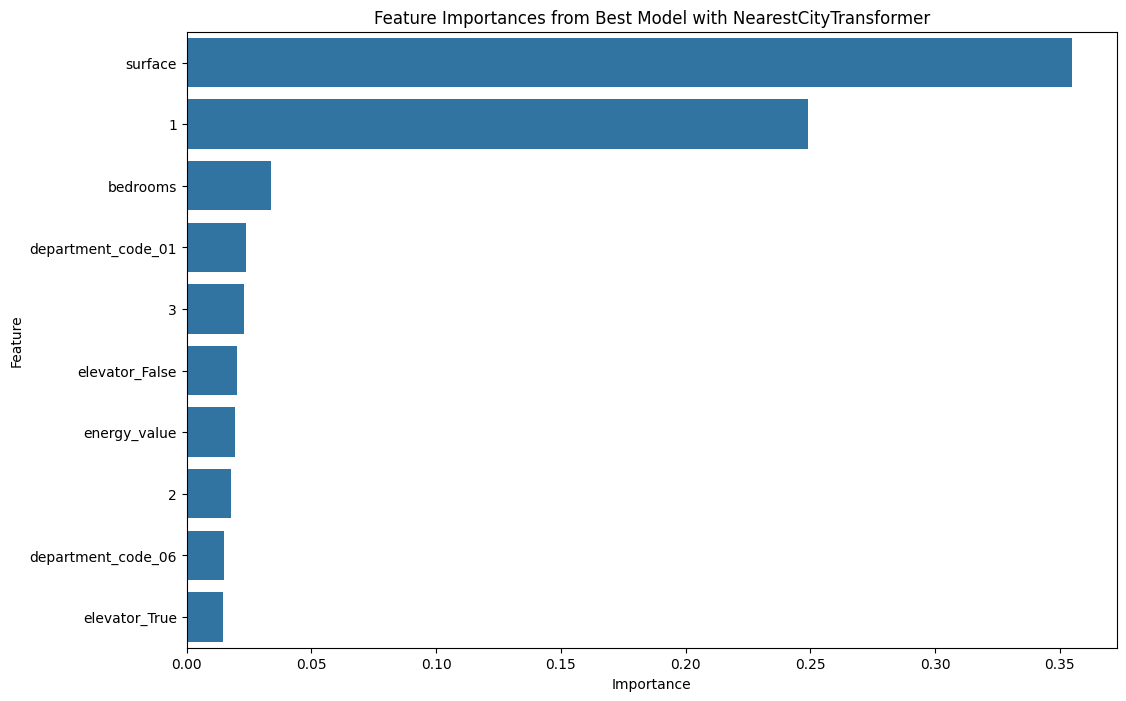

In [24]:
# Importance des features
feature_names = (list(["1", "2", "3"]) +
                 [f for f in numerical_features if f not in geo_features] +
                 list(best_model.named_steps['preprocessor'].transformers_[2][1].get_feature_names_out(categorical_features)))
importances = best_model.named_steps['regressor'].feature_importances_
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
# head 10 features
f = feature_importance_df.head(10)
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=f)
plt.title('Feature Importances from Best Model with NearestCityTransformer')
plt.show()


In [25]:
best_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('geo',
                                                  Pipeline(steps=[('geo_features',
                                                                   NearestCityTransformer())]),
                                                  ['lat', 'lon']),
                                                 ('num', 'passthrough',
                                                  ['surface', 'rooms',
                                                   'bedrooms', 'bathrooms',
                                                   'showers', 'floor',
                                                   'balconies', 'terraces',
                                                   'parking_places', 'cellars',
                                                   'energy_value', 'ghg_value',
                                                   'energy_min_cost',
                                                   'energy_max_cost']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['city', 'postal_code',
                                                   'department_code',
                                                   'elevator',
                                                   'disabled_access',
                                                   'furnished', 'duplex',
                                                   'energy_class', 'ghg_class',
                                                   'heating_type',
                                                   'new_property'])])),
                ('regressor',
                 GradientBoostingRegressor(max_depth=5, n_estimators=800))])

### Conclusion

Le projet a réussi à construire un pipeline fonctionnelle de prédiction immobilière, avec une collecte de données réelles (2 000+ annonces via l’API Bien’ici), un prétraitement adapté (gestion des NaN, sélection de 28 features pertinentes), et une modélisation réfléchie (comparaison de 7 algorithmes, optimisation par GridSearchCV, métriques MSE/R²). 

Limites identifiées : 
Données : 1500 lignes léger pour un projet pareil.
Features : OneHotEncoding peu scalable, texte des descriptions non exploité.

Améliorations prioritaires :
Élargir les données : Intégrer SeLoger, Leboncoin, et des données macro-économiques (INSEE, OpenStreetMap). 
Feature engineering : Ajouter des ratios (prix/m²), des analyses de texte (TF-IDF), et des données géolocalisées (transports, écoles). 
Modélisation : Tester d’autres modèles

Résultats actuels : Les modèles comme Gradient Boosting et Random Forest offrent un bon compromis, tandis que la régression linéaire et KNN sont moins adaptés. Le R² (~0.7-0.8) est encourageant pour un prototype, mais nécessite une montée en échelle (20 000+ annonces, couverture nationale).